In [1]:
from dotenv import load_dotenv
import pymongo
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


In [2]:
import os
load_dotenv()
CONNECTION_STRING=os.getenv('uri')

client=pymongo.MongoClient(CONNECTION_STRING)
db=client['Proj1']
collection=db['Proj1-Data']

data=collection.find({})

df=pd.DataFrame(list(data))
if '_id' in df.columns:
    df=df.drop(columns=['_id'])

In [3]:
df.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


In [4]:
df.isna().sum()

id                      0
Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
Response                0
dtype: int64

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  object 
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  object 
 7   Vehicle_Damage        381109 non-null  object 
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 34.9+ MB


In [6]:
df.describe()

,id,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Response
count,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000
mean,190555.000000,38.822584,0.997869,26.388807,0.458210,30564.389581,112.034295,154.347397,0.122563
std,110016.836208,15.511611,0.046110,13.229888,0.498251,17213.155057,54.203995,83.671304,0.327936
min,1.000000,20.000000,0.000000,0.000000,0.000000,2630.000000,1.000000,10.000000,0.000000
25%,95278.000000,25.000000,1.000000,15.000000,0.000000,24405.000000,29.000000,82.000000,0.000000
50%,190555.000000,36.000000,1.000000,28.000000,0.000000,31669.000000,133.000000,154.000000,0.000000
75%,285832.000000,49.000000,1.000000,35.000000,1.000000,39400.000000,152.000000,227.000000,0.000000
max,381109.000000,85.000000,1.000000,52.000000,1.000000,540165.000000,163.000000,299.000000,1.000000


- **Gender**: Boolean feature (Currently in text needs to be numerical)
- **Age**: Numerical feature (needs to be scaled)
- **Driving_licence**: boolean feature. (97% yes might need to be removed)
- **Region_code**: catagorical feature (needs to be encoded target encoding or frequency encoding)
- **Previously_insured**: boolean feature (no change required)
- **Vehicle_age**: 3 catagorical featrue (Ordinal encoding or OneHotEncoding)
- **Vehicle_damage**: bolean feature (currently in text need to be numerical)
- **Annual_Premium**: numerical feature (needs to be scaled , skewed towards right use **Robustscaler** to counter extreme outliers)
- **Policy_Sales_channel**: catagorical feature (needs to be encoded)
- **Vintage numerical**: numerical feature (needs to be scaled)
- **Response**: Target (only 12% yes needs to be handled)

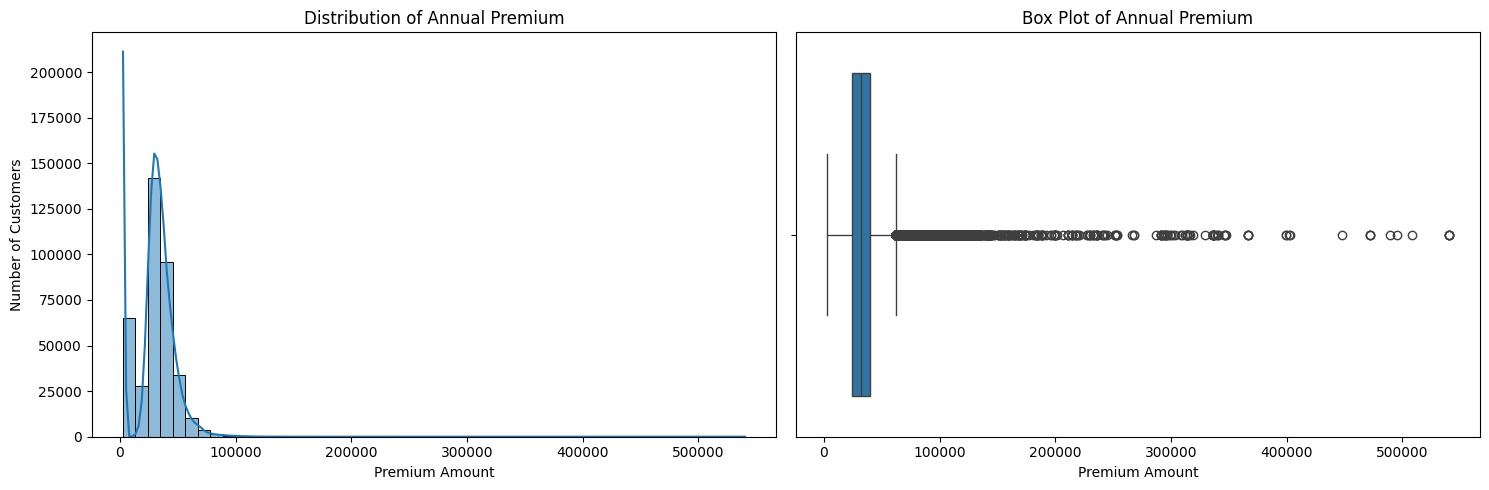

In [7]:
import seaborn as sns

# Set up a figure with two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Histogram (to see the skew)
sns.histplot(df['Annual_Premium'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Annual Premium')
axes[0].set_xlabel('Premium Amount')
axes[0].set_ylabel('Number of Customers')

# Plot 2: Box Plot (to see the extreme outliers)
sns.boxplot(x=df['Annual_Premium'], ax=axes[1])
axes[1].set_title('Box Plot of Annual Premium')
axes[1].set_xlabel('Premium Amount')

plt.tight_layout()
plt.show()

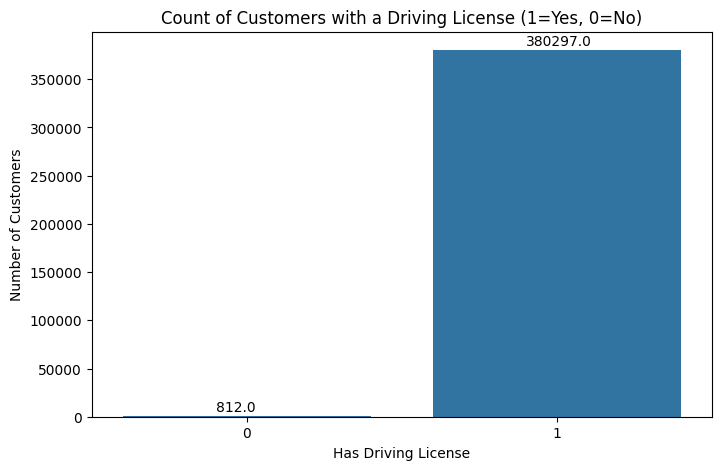

In [8]:
plt.figure(figsize=(8, 5))

# Plot: Countplot (to see class imbalance)
sns.countplot(data=df, x='Driving_License')
plt.title('Count of Customers with a Driving License (1=Yes, 0=No)')
plt.xlabel('Has Driving License')
plt.ylabel('Number of Customers')

# Optional: Add exact numbers on top of the bars to see just how extreme it is
ax = plt.gca()
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + 0.3, p.get_height() + 5000))

plt.show()

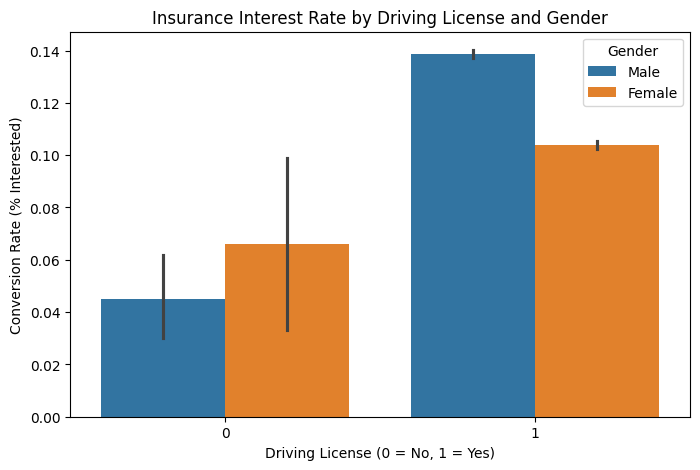

In [9]:
plt.figure(figsize=(8, 5))

# Plot the conversion rate (mean response) by License and Gender
sns.barplot(data=df, x='Driving_License', y='Response', hue='Gender')

plt.title('Insurance Interest Rate by Driving License and Gender')
plt.xlabel('Driving License (0 = No, 1 = Yes)')
plt.ylabel('Conversion Rate (% Interested)')

plt.show()

<Axes: xlabel='Gender', ylabel='Response'>

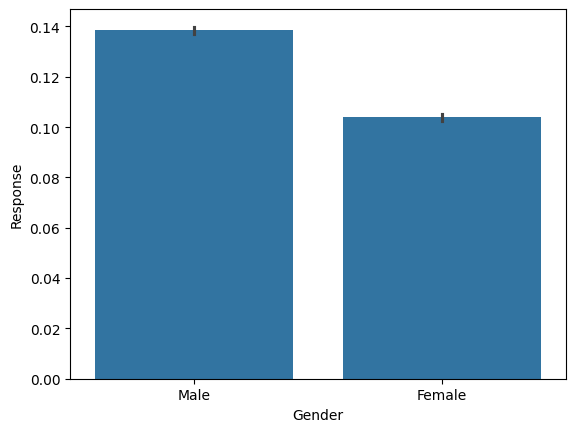

In [10]:
sns.barplot(data=df,x='Gender',y='Response')

<Axes: xlabel='Response', ylabel='count'>

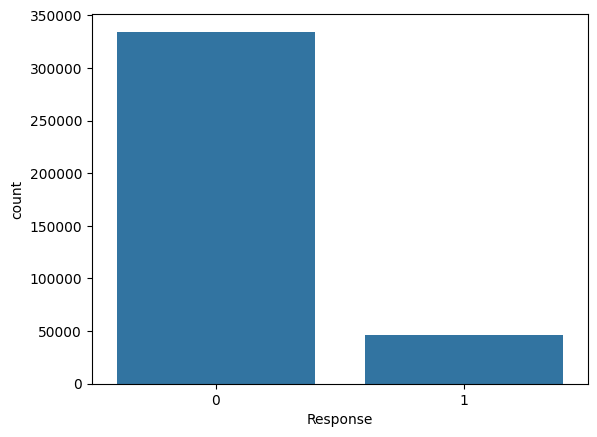

In [11]:
sns.countplot(data=df,x='Response')

In [12]:
df.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


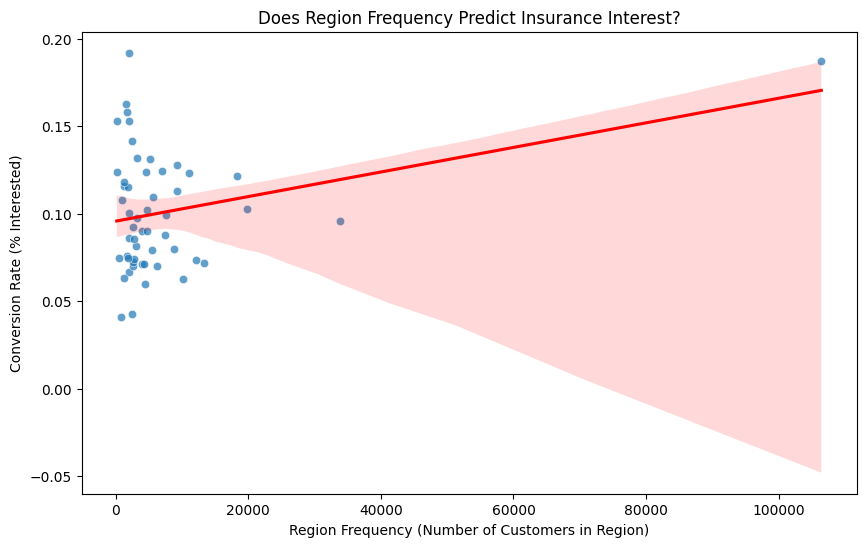

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Group the data by Region_Code to calculate both the Frequency and the Conversion Rate
region_stats = df.groupby('Region_Code').agg(
    frequency=('Region_Code', 'count'),          # How many times the region appears
    conversion_rate=('Response', 'mean')         # The percentage of '1's in that region
).reset_index()

# 2. Plot the relationship
plt.figure(figsize=(10, 6))

# Create a scatter plot of every region
sns.scatterplot(data=region_stats, x='frequency', y='conversion_rate', alpha=0.7)

# Add a trendline (regression line) to instantly see if a correlation exists
sns.regplot(data=region_stats, x='frequency', y='conversion_rate', scatter=False, color='red')

plt.title('Does Region Frequency Predict Insurance Interest?')
plt.xlabel('Region Frequency (Number of Customers in Region)')
plt.ylabel('Conversion Rate (% Interested)')

plt.show()

In [14]:
df['Gender']=df['Gender'].map({'Female': 0,'Male': 1}).astype(int)
df['Vehicle_Damage']=df['Vehicle_Damage'].map({'No': 0,'Yes': 1}).astype(int)
df.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,1,44,1,28.0,0,> 2 Years,1,40454.0,26.0,217,1
1,2,1,76,1,3.0,0,1-2 Year,0,33536.0,26.0,183,0
2,3,1,47,1,28.0,0,> 2 Years,1,38294.0,26.0,27,1
3,4,1,21,1,11.0,1,< 1 Year,0,28619.0,152.0,203,0
4,5,0,29,1,41.0,1,< 1 Year,0,27496.0,152.0,39,0


In [15]:
#Ordinal encoding vehicale age which is a categorical feature

from sklearn.preprocessing import OrdinalEncoder

age_order=[['< 1 Year','1-2 Year','> 2 Years']]
ord_enc=OrdinalEncoder(categories=age_order)
df['Vehicle_Age']=ord_enc.fit_transform(df[['Vehicle_Age']])


In [16]:
'''frequency encoding does not work in this case so we will target encode instead'''

#frequecy encoding Policy_Sales_Channel as it is a cataegorical feature with high max value

# channel_frequencies=df['Policy_Sales_Channel'].value_counts().to_dict()
# df['Policy_Sales_Channel']=df['Policy_Sales_Channel'].map(channel_frequencies)


'frequency encoding does not work in this case so we will target encode instead'

In [17]:
'''same here we will target encode instead'''
#frequency ecoding Region_Code aswell 

# channel_frequencies_rc=df['Region_Code'].value_counts().to_dict()
# df['Region_Code']=df['Region_Code'].map(channel_frequencies_rc)

'same here we will target encode instead'

In [18]:
df.drop(columns=['id'],inplace=True)

In [19]:
#performing train_test_split

from sklearn.model_selection import train_test_split


X=df.drop(columns=['Response'])
y=df['Response']

X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,test_size=0.2)

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,RobustScaler,TargetEncoder

ss_cols=['Age','Vintage']
rs_cols=['Annual_Premium']
target_en_cols=['Policy_Sales_Channel','Region_Code']

preprocessor=ColumnTransformer(
    transformers=[
    ('target_encoder',TargetEncoder(target_type='binary'),target_en_cols),
    ('standerd_scaler',StandardScaler(),ss_cols),
    ('robust_scaler',RobustScaler(),rs_cols)
    ],
    remainder='passthrough'
)

preprocessor.set_output(transform='pandas')

X_train_processed=preprocessor.fit_transform(X_train,y_train)

#only transform on X_test to sop data_leaking
X_test_processed=preprocessor.transform(X_test)

# This removes everything before (and including) the "__" in the column names
X_train_processed.columns = X_train_processed.columns.str.split('__').str[-1]
X_test_processed.columns = X_test_processed.columns.str.split('__').str[-1]


In [21]:
X_train_processed

,Policy_Sales_Channel,Region_Code,Age,Vintage,Annual_Premium,Gender,Driving_License,Previously_Insured,Vehicle_Age,Vehicle_Damage
332803,0.159793,0.069793,0.010601,0.869505,1.414693,0,1,0,1.0,1
116248,0.198096,0.109544,-0.053875,-1.497719,-0.575512,1,1,0,1.0,1
255005,0.028347,0.075195,-1.085502,0.140209,0.909079,1,1,1,0.0,0
317474,0.037289,0.126127,-1.021025,1.467289,-0.169449,0,1,1,0.0,0
344212,0.244482,0.102763,1.106704,0.008696,-1.935366,1,1,0,2.0,1
...,...,...,...,...,...,...,...,...,...,...
259178,0.028783,0.078114,-0.956548,1.586846,-0.606363,0,1,1,0.0,0
365838,0.186728,0.124802,1.106704,1.718359,0.640480,1,1,0,1.0,1
131932,0.028420,0.073598,-1.085502,-0.935802,-0.854106,0,1,0,0.0,1
146867,0.216964,0.085374,0.332984,-1.234694,-1.935366,1,1,1,1.0,1


In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

random_search = {'criterion': ['entropy', 'gini'],
               'max_depth': [2,3,4,5,6,7,10],
               'min_samples_leaf': [4, 6, 8],
               'min_samples_split': [5, 7,10],
               'n_estimators': [300]}

clf=RandomForestClassifier()

model=RandomizedSearchCV(estimator=clf,param_distributions=random_search,n_iter=10,cv=4,verbose=1,
                         random_state=101,n_jobs=-1)

model.fit(X_train_processed,y_train)

Fitting 4 folds for each of 10 candidates, totalling 40 fits


,estimator,RandomForestClassifier()
,param_distributions,"{'criterion': ['entropy', 'gini'], 'max_depth': [2, 3, ...], 'min_samples_leaf': [4, 6, ...], 'min_samples_split': [5, 7, ...], ...}"
,n_iter,10
,scoring,None
,n_jobs,-1
,refit,True
,cv,4
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,101
,error_score,nan


In [23]:
best_params=model.best_params_
best_params

{'n_estimators': 300,
 'min_samples_split': 7,
 'min_samples_leaf': 6,
 'max_depth': 10,
 'criterion': 'entropy'}

In [24]:
import pickle
file_name='rf_model.pkl'
pickle.dump(model,open(file_name,'wb'))

In [25]:
rf_load=pickle.load(open(file_name,'rb'))

In [27]:
from sklearn.metrics import classification_report

y_pred=model.predict(X_test_processed)

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.88      1.00      0.93     66699
           1       0.00      0.00      0.00      9523

    accuracy                           0.88     76222
   macro avg       0.44      0.50      0.47     76222
weighted avg       0.77      0.88      0.82     76222



c:\Anaconda file\envs\vehicle\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Anaconda file\envs\vehicle\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Anaconda file\envs\vehicle\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [30]:
model2=RandomForestClassifier(class_weight='balanced',n_estimators=300,min_samples_split=7,
                              min_samples_leaf=6,max_depth=10,criterion='entropy')

model2.fit(X_train_processed,y_train)



,n_estimators,300
,criterion,'entropy'
,max_depth,10
,min_samples_split,7
,min_samples_leaf,6
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [32]:
y_pred2=model2.predict(X_test_processed)

print(classification_report(y_test,y_pred2))

              precision    recall  f1-score   support

           0       0.99      0.67      0.80     66699
           1       0.29      0.93      0.44      9523

    accuracy                           0.70     76222
   macro avg       0.64      0.80      0.62     76222
weighted avg       0.90      0.70      0.75     76222



In [33]:
file_name2='rf_model2.pkl'
pickle.dump(model2,open(file_name2,'wb'))
rf_load=pickle.load(open(file_name2,'rb'))